# 图

输出到 `figures/`。先运行初始化格；其余各格只依赖它，顺序随意。
热图和方差曲线读 `results/` 下的 CSV；箱线图和 PC1 分位点上的图像用初始化格里算好的 PC1 得分。
格式由初始化格的 `FORMAT` 决定：放 PPT 用 svg，放 LaTeX 用 pdf。

In [1]:
import pandas as pd

from fmspace.analysis import l2, pca, zscore
from fmspace.data import load_metadata
from fmspace.extract import load_features
from fmspace.models import MODELS
from fmspace.paths import DATA_DIR, FEATURE_DIR, FIGURE_DIR, RESULT_DIR
from fmspace.plots import grade_boxplot, heatmap, pc_quantiles, variance_curve

FORMAT = "svg"

metadata = load_metadata(DATA_DIR)
y = metadata["eye_dr_level"].to_numpy()
pc1 = {}  # PC1 得分，z-score，方向调成与 DR 正相关
for name in MODELS:
    X = l2(load_features(FEATURE_DIR / f"{name}.npz", metadata["image_id"]))
    pc1[name] = zscore(pca(X).transform(X)[:, 0], y)

c:\M1\envs\fmspace\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## PC × 标签热图

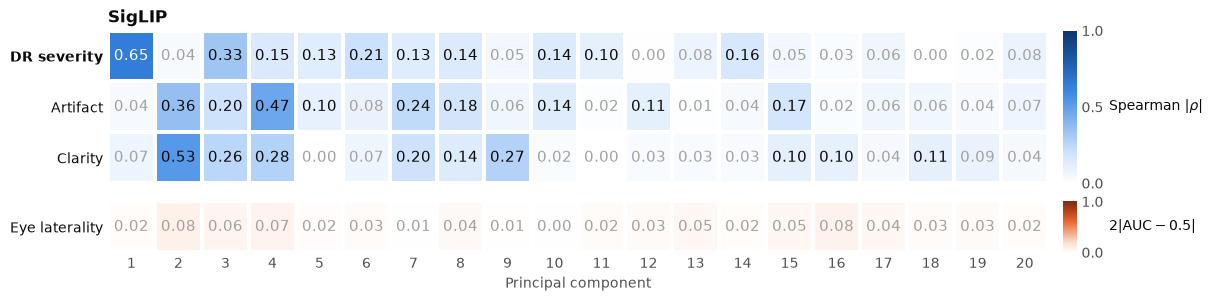

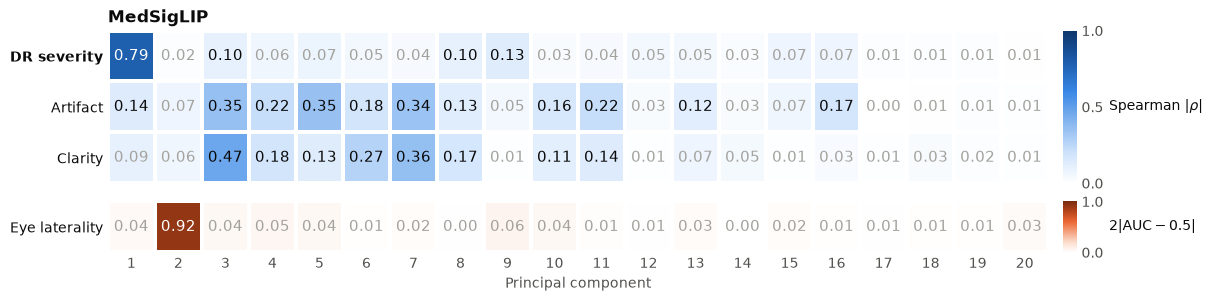

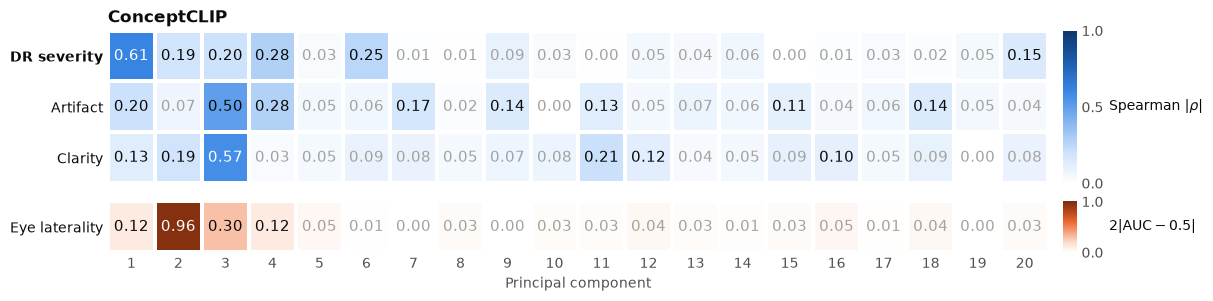

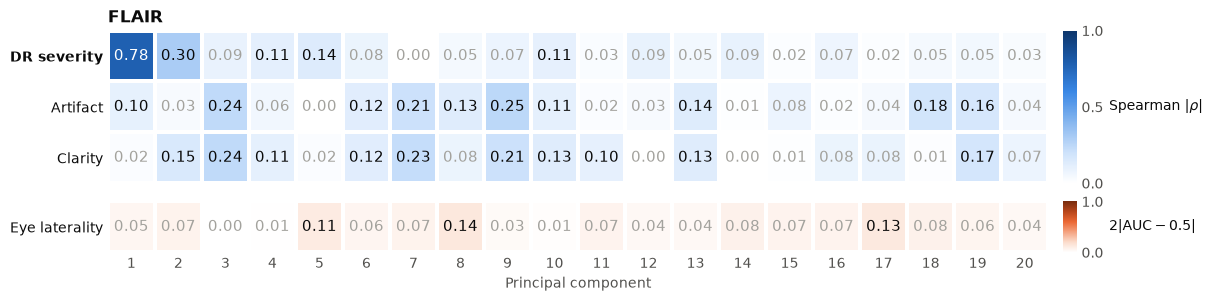

In [2]:
assoc = pd.read_csv(RESULT_DIR / "pc_association.csv")
for name in MODELS:
    fig = heatmap(assoc, name, ["eye_dr_level", "artifact", "clarity", "eye"])
    fig.savefig(FIGURE_DIR / f"heatmap_{name}.{FORMAT}", bbox_inches="tight")

## 累计解释方差

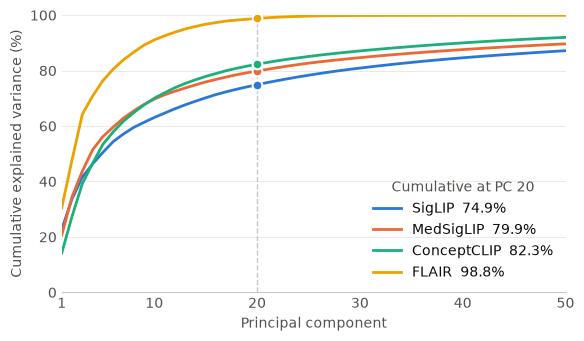

In [3]:
variance = pd.read_csv(RESULT_DIR / "explained_variance.csv")
fig = variance_curve(variance, list(MODELS), n_pcs=50, mark=20)
fig.savefig(FIGURE_DIR / f"variance_cumulative.{FORMAT}", bbox_inches="tight")

## 各等级在 PC1 上的箱线图（4 个模型并排）

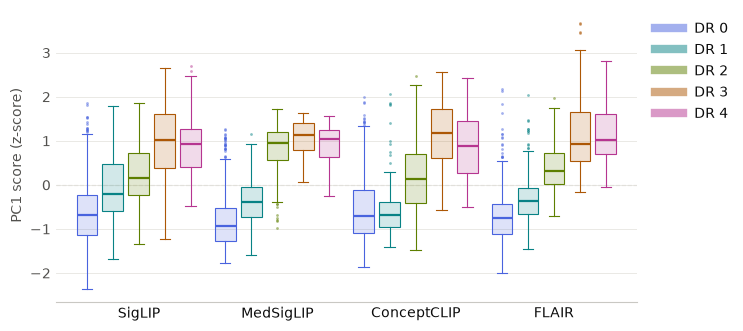

In [4]:
fig = grade_boxplot(pc1, y, list(MODELS))
fig.savefig(FIGURE_DIR / f"boxplot_pc1.{FORMAT}", bbox_inches="tight")

## PC1 分位点上的图像

在全部图像 PC1 得分的 5 / 25 / 50 / 75 / 95% 分位点上，图下的数字是该分位点前后 5 个百分点内全部图像（约 120 张）的中位 DR 等级。
图像从同一范围内、等级等于该中位数、无伪影（Artifact 0）且最清晰（Clarity 10）的图像里，取得分最接近分位点的一张。

In [ ]:
clean = ((metadata["artifact"] == 0) & (metadata["clarity"] == 10)).to_numpy()
fig = pc_quantiles(pc1, metadata, list(MODELS), mask=clean)
fig.savefig(FIGURE_DIR / f"pc1_quantiles.{FORMAT}", bbox_inches="tight", dpi=200)